# Laboratorium 03 — Diagnostyka procesu uczenia

Na tych zajęciach poznajemy **Keras**: budujemy, trenujemy i oceniamy sieć
neuronową.

**Zaczynamy od vanilla MLP**: warstwy gęste, optymalizator Adam i koszt BCE.
Najpierw obserwujemy przebieg uczenia i granicę decyzji. Potem rozwijamy
kod, dodając L2, wygaszanie wag, dropout oraz callbacki.
Po każdej zmianie uczymy nowy model i zapisujemy wykresy do porównania.

Pracujemy na **dwóch spiralach z około 10% losowo odwróconych etykiet**,
które symulują błędy oznaczeń. Zachowujemy ten sam podział danych
i ziarna losowania. Zmieniamy `RUN_NAME`, żeby zachować wyniki kolejnych
eksperymentów. Notebook można uruchomić w Google Colab na CPU.

In [1]:
# VANILLA: punkt startowy
from pathlib import Path  # ścieżki
import numpy as np  # tablice; losowanie
import matplotlib.pyplot as plt  # wykresy
from sklearn.model_selection import train_test_split  # podział danych
from sklearn.preprocessing import StandardScaler  # standaryzacja
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.initializers import HeNormal, GlorotUniform
from tensorflow.keras.regularizers import L2
from tensorflow.keras.optimizers import Adam, AdamW, SGD
from tensorflow.keras.callbacks import (
    ReduceLROnPlateau, EarlyStopping, ModelCheckpoint, CSVLogger,
)
from tensorflow.keras import losses, metrics  # koszt; metryki
from tensorflow.keras.backend import clear_session
from tensorflow.keras.utils import set_random_seed

## 1. Dane i błędne etykiety

Promień `r` i kąt `angle` tworzą dwie spirale o dwóch zwojach.
`NOISE` określa szum współrzędnych. `LABEL_NOISE` określa
prawdopodobieństwo odwrócenia etykiety 0 ↔ 1.
Losowanie maski nie gwarantuje dokładnie 100 zmienionych etykiet.

Podział **70/15/15%**: 700 próbek treningowych, 150 walidacyjnych,
150 testowych. `stratify` zachowuje proporcje obserwowanych klas.
Scaler dopasowujemy tylko na treningu. Test czeka do końcowej oceny.

**Pytania do omówienia:**
- Czy zapamiętanie błędnych etykiet pomoże na nowych danych?
- Dlaczego zachowujemy ten sam podział danych przy porównywaniu metod?
- Czy oczekujesz 100% accuracy na nowych próbkach, skoro część etykiet jest błędna?

In [2]:
rng = np.random.default_rng(2026)  # spirale; generator; ziarno
t = rng.uniform(0, 1, 1000)  # położenie na spirali
y = np.arange(1000) % 2  # klasy 0/1
r = 0.5 + 4.5 * t  # promień
angle = 2 * np.pi * 2 * t + np.pi * y  # kąt; obrót π
X = np.column_stack([r * np.cos(angle), r * np.sin(angle)])  # próbki × 2
X += rng.normal(0, 0.1, X.shape)  # szum normalny

changed_labels = rng.random(1000) < 0.1  # maska błędnych etykiet
y[changed_labels] = 1 - y[changed_labels]  # 0 ↔ 1

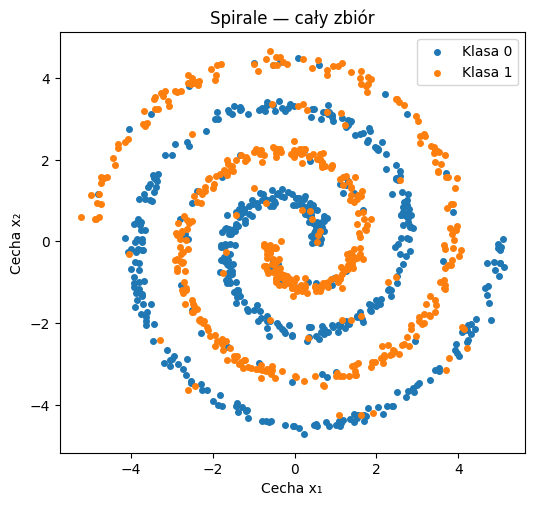

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))  # rysunek; osie
ax.scatter(X[y == 0, 0], X[y == 0, 1],  # klasy; współrzędne
           s=16, color="tab:blue", label="Klasa 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1],
           s=16, color="tab:orange", label="Klasa 1")
ax.set(xlabel="Cecha x₁", ylabel="Cecha x₂", title="Spirale — cały zbiór")
ax.set_aspect("equal")  # równa skala
ax.legend()
plt.show()

In [4]:
X_train, X_hold, y_train, y_hold = train_test_split(  # trening 70%; proporcje klas; stały podział
    X, y, test_size=0.30, stratify=y, random_state=2026,
)
X_val, X_test, y_val, y_test = train_test_split(  # walidacja 15%; test 15%; wybór; ocena
    X_hold, y_hold, test_size=0.5, stratify=y_hold, random_state=2026,
)

y_train = y_train.astype("float32").reshape(-1, 1)  # float32; etykiety: kolumna
y_val = y_val.astype("float32").reshape(-1, 1)
y_test = y_test.astype("float32").reshape(-1, 1)

scaler = StandardScaler()  # standaryzacja
X_train_s = scaler.fit_transform(X_train).astype("float32")  # dopasowanie: tylko trening
X_val_s = scaler.transform(X_val).astype("float32")  # ten sam scaler
print("Trening / walidacja / test:", len(X_train), len(X_val), len(X_test))

Trening / walidacja / test: 700 150 150


## 2. Budujemy gęstą sieć neuronową

Dwie cechy → trzy warstwy po 256 neuronów z ReLU → sigmoida.
`Sequential` łączy warstwy w kolejności, a `Dense` uczy ich wagi i biasy.
ReLU wprowadza nieliniowość; sigmoida daje prawdopodobieństwo klasy 1.

**Na początek używamy samych warstw gęstych**, bez dropout i kary L2.
Sieć ma 132 609 parametrów. Chcemy zobaczyć, jak duży model uczy się
spiral i czy zaczyna dopasowywać również błędy etykiet.
L2 i dropout dodamy po uruchomieniu i ocenie tego wariantu.

**Pytania do omówienia:**

- Które wartości wybieramy sami: liczbę neuronów, wagi czy biasy? Których uczy się model?
- Dlaczego na wyjściu jest jeden neuron, mimo że mamy dwie klasy?

In [49]:
RUN_NAME = "03_vanilla"  # eksperyment; folder
output_dir = Path("wyniki_lab_03_regularyzacja") / RUN_NAME
output_dir.mkdir(parents=True, exist_ok=True)  # folder wyników

clear_session()  # reset modelu
set_random_seed(2026)  # ziarno treningu

model = Sequential([  # warstwy kolejno
    Input(shape=(2,)),  # 2 cechy
    Dense(
        64, activation="relu",  # ReLU: nieliniowość
        kernel_initializer=HeNormal(seed=2026),  # HeNormal: ReLU
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2027),
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2028),
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2030),
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2031),
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2032),
    ),
    Dense(
        64, activation="relu",
        kernel_initializer=HeNormal(seed=2033),
    ),
    Dense(
        1, activation="sigmoid",  # P(klasa 1)
        kernel_initializer=GlorotUniform(seed=2029),  # GlorotUniform
    ),
])
print("Liczba parametrów:", model.count_params())

Liczba parametrów: 25217


## 3. Ustalamy sposób uczenia

Zaczynamy z optymalizatorem **Adam** z `learning_rate = 0.003`.
Optymalizator zmienia wagi na podstawie gradientu — pochodnych kosztu
względem parametrów. `compile` ustala sposób uczenia, ale jeszcze go nie wykonuje.

Kosztem jest **BCE**: niższa wartość oznacza lepsze przewidywane
prawdopodobieństwa. `accuracy` mierzy odsetek poprawnych klas przy progu 0.5.
Metrykę `bce` zapisujemy osobno, aby później porównać modele również po dodaniu L2.

W kolejnych eksperymentach zastąpimy Adam przez **AdamW**, który osobno
wygasza wagi. Sprawdzimy też, czym różni się to od dodania kary L2 do kosztu.

**Pytania do omówienia:**

- Dla próbki klasy 1 dwa modele przewidują p = 0.51 i p = 0.99. Czy accuracy odróżni te przewidywania? A BCE?
- Zwiększamy learning rate 100 razy. Jak może zmienić się przebieg BCE?

In [50]:
optimizer = Adam(learning_rate=0.003)  # Adam
# OPCJA SGD: optimizer = SGD(learning_rate=0.003, momentum=0.9)
model.compile(  # konfiguracja treningu
    optimizer=optimizer,
    loss=losses.BinaryCrossentropy(),  # BCE
    metrics=[  # metryki; BCE bez L2; accuracy: próg 0.5
        metrics.BinaryCrossentropy(name="bce"),
        metrics.BinaryAccuracy(name="accuracy"),
    ],
)

## 4. Trening

`fit` aktualizuje wagi na treningu. Jedna **epoka** to przejście po całym
zbiorze treningowym, a **mini-batch** to partia 32 próbek używana w jednej aktualizacji.
Po każdej epoce oceniamy walidację, bez uczenia na jej próbkach.

**Pierwszy model uczymy przez 400 epok, bez callbacków.**
`History` zachowuje wyniki kolejnych epok. Na ich podstawie narysujemy wykresy.
Najpierw porównamy L2, AdamW i dropout przy tym samym budżecie epok.

Dopiero później dodamy **callbacki**, czyli obiekty reagujące podczas treningu:
zapis modelu i historii, early stopping oraz zmniejszanie learning rate.

**Pytania do omówienia:**

- Mamy 700 próbek i batch size 32. Ile aktualizacji wag wykonamy w jednej epoce? Czy ostatnia partia będzie pełna?
- Czy podczas obliczania wyniku walidacyjnego model powinien zmieniać wagi? Dlaczego?

In [56]:
history = model.fit(  # trening; historia
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),  # walidacja; bez gradientów
    epochs=46, batch_size=32,
    shuffle=True,  # tasowanie
    verbose=1,  # 1: postęp
)

Epoch 1/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9129 - bce: 0.2568 - loss: 0.2568 - val_accuracy: 0.8867 - val_bce: 0.4299 - val_loss: 0.4299
Epoch 2/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9129 - bce: 0.2473 - loss: 0.2473 - val_accuracy: 0.8800 - val_bce: 0.4648 - val_loss: 0.4648
Epoch 3/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9029 - bce: 0.2434 - loss: 0.2434 - val_accuracy: 0.8667 - val_bce: 0.5149 - val_loss: 0.5149
Epoch 4/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9100 - bce: 0.2503 - loss: 0.2503 - val_accuracy: 0.8733 - val_bce: 0.4263 - val_loss: 0.4263
Epoch 5/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9100 - bce: 0.2524 - loss: 0.2524 - val_accuracy: 0.8867 - val_bce: 0.4355 - val_loss: 0.4355
Epoch 6/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9143 - bce: 0.2503 - loss: 0.2503 - val_accuracy: 0.8667 - val_bce: 0.4989 - val_loss: 0.4989
Epoch 7/46
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/

## 5. Wyniki

Rysujemy **BCE treningowe i walidacyjne** oraz **granicę decyzji**.
Każdy wariant zapisujemy pod innym `RUN_NAME`.

Pionowa linia na historii oznacza minimum walidacji.
Po dodaniu early stopping z `restore_best_weights=True` oceniamy najlepsze wagi.

**Pytania do omówienia:**
- Co oznacza spadek BCE treningowego przy wzroście walidacyjnego?
- Czy na granicy decyzji widać drobne obszary dopasowane do błędnych etykiet?
- Którą epokę wybralibyśmy na podstawie walidacji? Czy zawsze będzie to ostatnia epoka?
- Model rozpoznaje prawie wszystkie punkty treningowe, ale ma gorszą walidację. Czy uznamy go za lepszy od modelu z wyższym błędem treningowym?

In [57]:
train_scores = model.evaluate(X_train_s, y_train, verbose=0, return_dict=True)  # ocena treningu
print(f"Trening: BCE={train_scores['bce']:.4f}; accuracy={train_scores['accuracy']:.3f}")

Trening: BCE=0.1842; accuracy=0.921


In [58]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)  # ocena walidacji
print(f"Walidacja: BCE={val_scores['bce']:.4f}; accuracy={val_scores['accuracy']:.3f}")

Walidacja: BCE=0.5918; accuracy=0.873


4


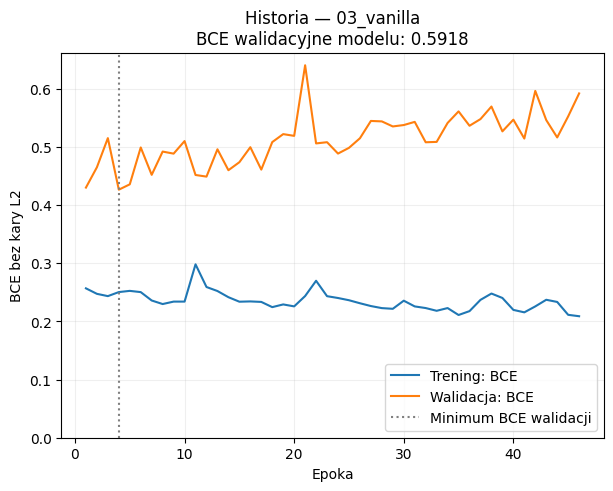

In [59]:
epochs = np.arange(1, len(history.history["bce"]) + 1)  # historia / epoka
best_epoch = int(np.argmin(history.history["val_bce"]) + 1)  # minimum walidacji; indeks + 1
print(best_epoch)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(epochs, history.history["bce"], label="Trening: BCE")  # trening
ax.plot(epochs, history.history["val_bce"], label="Walidacja: BCE")  # walidacja
ax.axvline(best_epoch, color="gray", linestyle=":", label="Minimum BCE walidacji")  # minimum walidacji; bez przywracania
ax.set(xlabel="Epoka", ylabel="BCE bez kary L2", title=f"Historia — {RUN_NAME}\nBCE walidacyjne modelu: {val_scores['bce']:.4f}")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(output_dir / "history_bce.png", dpi=150, bbox_inches="tight")  # zapis PNG
plt.show()

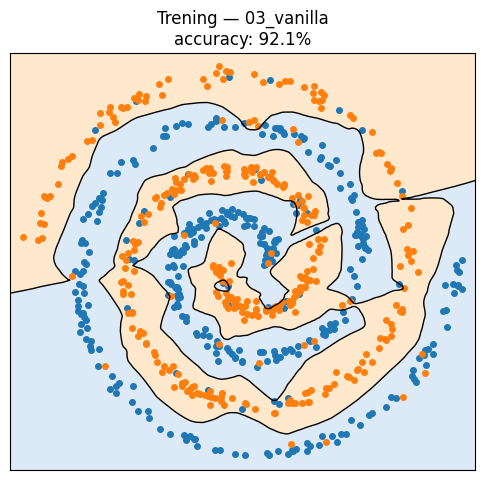

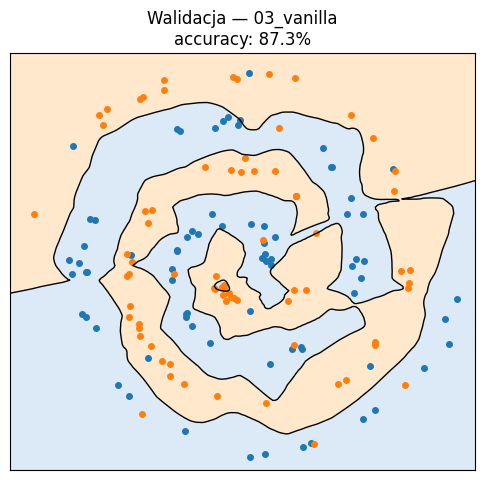

In [60]:
visible = np.vstack([X_train, X_val])  # zakres: trening + walidacja
x1 = np.linspace(visible[:, 0].min() - 0.3, visible[:, 0].max() + 0.3, 201)  # siatka punktów
x2 = np.linspace(visible[:, 1].min() - 0.3, visible[:, 1].max() + 0.3, 201)
grid_x1, grid_x2 = np.meshgrid(x1, x2)  # pary współrzędnych; punkty × 2
grid = np.column_stack([grid_x1.ravel(), grid_x2.ravel()])
grid_s = scaler.transform(grid).astype("float32")  # ten sam scaler
probability = model.predict(grid_s, batch_size=1024, verbose=0).reshape(grid_x1.shape)  # predykcja na siatce

def plot_boundary(X_points, y_points, title, filename):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.contourf(grid_x1, grid_x2, probability,  # klasy
                levels=[0, 0.5, 1], colors=["#dce9f7", "#ffe8cc"])
    ax.contour(grid_x1, grid_x2, probability,  # granica p = 0.5
               levels=[0.5], colors="black", linewidths=1)
    ax.scatter(X_points[y_points.ravel() == 0, 0],
               X_points[y_points.ravel() == 0, 1], s=16, color="tab:blue")
    ax.scatter(X_points[y_points.ravel() == 1, 0],
               X_points[y_points.ravel() == 1, 1], s=16, color="tab:orange")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_boundary(X_train, y_train, f"Trening — {RUN_NAME}\naccuracy: {train_scores['accuracy']:.1%}",
              "granica_decyzji_trening.png")
plot_boundary(X_val, y_val, f"Walidacja — {RUN_NAME}\naccuracy: {val_scores['accuracy']:.1%}",
              "granica_decyzji_walidacja.png")

## 6. Rozwijamy kod przez kolejne eksperymenty

**Po każdej zmianie uruchamiamy notebook od góry**, tworząc nowy model
i optymalizator. Po treningu zapisujemy historię BCE oraz granicę decyzji.
Dane, podział, ziarna i architekturę zachowujemy.

### Punkt wyjścia — vanilla

`RUN_NAME = "00_vanilla"`. Trzy warstwy gęste, Adam, 400 epok,
bez L2, dropout, wygaszania, przycinania gradientu i callbacków.
Zachowujemy oba wykresy jako punkt odniesienia.

### Dodajemy L2

Do trzech warstw ukrytych dodajemy `kernel_regularizer=keras.regularizers.L2(...)`,
ze współczynnikiem `1e-4`. Kara za duże wagi może ograniczać dopasowywanie
drobnych wyjątków. Używamy Adama, bez pozostałych dodatków.
Czy błąd treningowy rośnie, a walidacyjny maleje?

**Pytania do omówienia:**

- Przed treningiem: jak bardzo silna kara L2 może wpłynąć na dopasowanie spiral?
- Po treningu: czy wyższe BCE treningowe z L2 jest problemem, jeśli BCE walidacyjne spadło?

### Dodajemy wygaszanie wag

Wracamy do vanilla i podmieniamy Adam na **AdamW** z `weight_decay = 0.10`.
AdamW zmniejsza wagi osobnym krokiem, także wagi ujemne przyciąga do zera.
Ten współczynnik nie jest zamiennikiem współczynnika L2.
Porównujemy sam AdamW z zapisanym wynikiem vanilla.

**Pytania do omówienia:**

- Co sam krok wygaszania zrobi z wagą -2: zbliży ją do zera czy uczyni bardziej ujemną?
- Dlaczego w tym porównaniu wyłączamy L2 i dropout?

### Dodajemy dropout

Ponownie zaczynamy od vanilla. Po każdej warstwie ukrytej dodajemy
`Dropout(0.15)`. Losowe zerowanie aktywacji utrudnia poleganie na
pojedynczych neuronach; Keras skaluje zachowane aktywacje.
Dropout podczas oceny jest wyłączony. Jak zmienia się granica decyzji?

**Pytania do omówienia:**

- Dlaczego Keras zwiększa zachowane aktywacje przez dzielenie przez 1 - p?
- Dlaczego nie chcemy losowo wyłączać aktywacji podczas przewidywania klasy nowego punktu?

### Łączymy techniki

Teraz sprawdzamy połączenie: L2 `1e-5`, AdamW `0.10`, dropout `0.10`.
Wciąż używamy 400 epok, bez early stopping i zmiany learning rate.
Czy połączenie daje lepszą walidację niż pojedyncze metody?

**Pytania do omówienia:**

- Gdybyśmy od razu włączyli trzy metody, skąd wiedzielibyśmy, która z nich pomogła?

### Dodajemy callbacki

Do wybranego wariantu dodajemy kolejno:

1. `ModelCheckpoint` i `CSVLogger` — zapis najlepszego modelu oraz historii.
2. `EarlyStopping` — zakończenie po 80 epokach bez poprawy `val_bce`
   i przywrócenie najlepszych wag.
3. `ReduceLROnPlateau` — zmniejszenie learning rate o połowę po
   20 epokach bez poprawy.

Callback musi być utworzony, dodany do listy i przekazany do `fit`.
Ten etap zmienia przebieg lub czas treningu, więc oceniamy go osobno
od wcześniejszego porównania metod przy 400 epokach.

**Pytania do omówienia:**

- Czy samo utworzenie `EarlyStopping` wystarczy, żeby zakończył uczenie? Gdzie jeszcze musimy go dodać?
- Czy `ModelCheckpoint` przywraca najlepsze wagi w pamięci, czy tylko zapisuje plik? Który callback przywraca wagi w naszym kodzie?
- Po zmniejszeniu learning rate: jakiej zmiany krzywych BCE oczekujemy? Czy muszą od razu zacząć maleć?

**Opcjonalnie:** przy zbyt dużych gradientach włączamy `clipnorm = 1.0`.
To przycinanie gradientu, a nie metoda zmniejszania wag.

**Pytania do omówienia:**

- Przycinamy gradient czy wagi? Czym różni się to od wygaszania wag?

**Na koniec porównujemy:** BCE walidacyjne, accuracy, liczbę wykonanych epok
i kształt granicy. Czy niższe BCE musi oznaczać wyższe accuracy?
Zbyt silna regularyzacja może prowadzić do niedouczenia.

## 7. Test po wyborze ustawień

Zbiór testowy wykorzystujemy dopiero do końcowej oceny wybranego modelu.
Podczas doboru ustawień korzystamy z walidacji.

**Pytania do omówienia:**

- Co byłoby nie tak z wybieraniem współczynnika L2 na podstawie wyniku testowego?

In [ ]:
# TEST: po wyborze modelu; bez strojenia na teście; scaler treningowy
# X_test_s = scaler.transform(X_test).astype("float32")
# test_scores = model.evaluate(X_test_s, y_test, verbose=0, return_dict=True)
# print(f"Test: BCE={test_scores['bce']:.4f}; accuracy={test_scores['accuracy']:.3f}")

Dokumentacja:
[L2 w Keras](https://keras.io/api/layers/regularizers/),
[AdamW](https://keras.io/api/optimizers/adamw/),
[Dropout](https://keras.io/api/layers/regularization_layers/dropout/),
[callbacki](https://keras.io/api/callbacks/).
Omówienie przeuczenia i regularyzacji:
[TensorFlow — Overfit and underfit](https://www.tensorflow.org/tutorials/keras/overfit_and_underfit).